# 01 — OULAD: análise exploratória

Fase 02 do EduGuard-IA. **Nenhum modelo é treinado.** Toda a lógica está em `src/`; este notebook apenas a executa e mostra os resultados. Associações aqui são descritivas, não causais.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_columns", 30, "display.width", 160)
FIG = ROOT / "research" / "figures"
from src.data.loaders import load_oulad, load_student_vle, OULAD_KEY
from src.data.quality import oulad_integrity
from src.feature_engineering import temporal
from src.analysis import eda, plots
t = load_oulad(); sv = load_student_vle(); base = temporal.student_base(t)
{k: v.shape for k, v in t.items()} | {'studentVle': sv.shape}

{'courses': (22, 3),
 'assessments': (206, 6),
 'vle': (6364, 6),
 'studentInfo': (32593, 12),
 'studentRegistration': (32593, 5),
 'studentAssessment': (173912, 5),
 'studentVle': (10655280, 6)}

## 1. Estrutura, granularidade e integridade das chaves

| Tabela | Granularidade (chave) |
|---|---|
| courses | módulo × apresentação |
| assessments | avaliação (`id_assessment`) |
| vle | material do AVA (`id_site`) |
| studentInfo / studentRegistration | estudante × módulo × apresentação |
| studentAssessment | estudante × avaliação |
| studentVle | estudante × material × dia (várias linhas por dia possíveis) |

In [2]:
integ = oulad_integrity(t, sv)
pd.DataFrame(integ['granularity']).T

,key,n_rows,n_duplicate_keys,unique
courses,"[code_module, code_presentation]",22,0,True
assessments,[id_assessment],206,0,True
vle,[id_site],6364,0,True
studentInfo,"[code_module, code_presentation, id_student]",32593,0,True
studentRegistration,"[code_module, code_presentation, id_student]",32593,0,True
studentAssessment,"[id_assessment, id_student]",173912,0,True
studentVle,"[code_module, code_presentation, id_student, i...",10655280,2195960,NaN


In [3]:
pd.Series(integ['orphans'], name='linhas órfãs')

assessments->courses                0
vle->courses                        0
studentInfo->courses                0
studentRegistration->studentInfo    0
studentInfo->studentRegistration    0
studentAssessment->assessments      0
studentAssessment->studentInfo      0
studentVle->studentInfo             0
studentVle->vle(id_site)            0
Name: linhas órfãs, dtype: int64

In [4]:
pd.Series(integ['consistency'], name='inconsistências')

withdrawn_without_unregistration_date     93
not_withdrawn_with_unregistration_date     9
unregistration_before_registration         0
registration_missing                      45
submissions_after_presentation_end        85
submissions_after_end_that_are_banked      0
Name: inconsistências, dtype: int64

In [5]:
per_student = t['studentInfo'].groupby('id_student').size()
print('estudantes em >1 apresentação:', (per_student > 1).sum(), 'de', per_student.size)
print('linhas totalmente duplicadas em studentVle:', sv.duplicated().sum())

estudantes em >1 apresentação: 3538 de 28785


linhas totalmente duplicadas em studentVle: 787170


## 2. Resultados acadêmicos

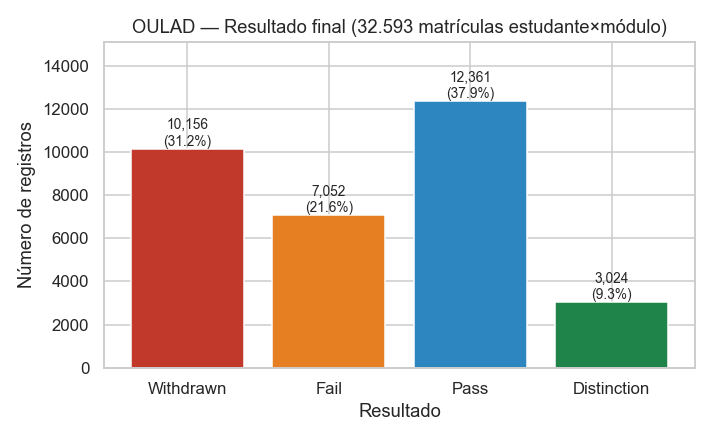

,count,proportion
final_result,,
Pass,12361,0.3793
Withdrawn,10156,0.3116
Fail,7052,0.2164
Distinction,3024,0.0928


In [6]:
plots.outcome_bars(base['final_result'].value_counts(), plots.OULAD_COLORS,
                    'OULAD — Resultado final (32.593 matrículas estudante×módulo)', FIG / 'oulad_outcome_distribution.png')
display(Image(FIG / 'oulad_outcome_distribution.png'))
eda.distribution(base['final_result'])

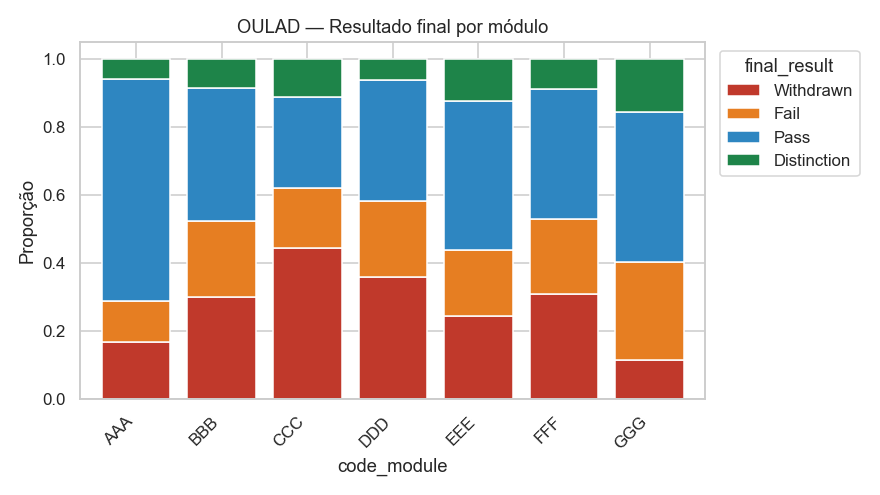

In [7]:
plots.outcome_share_by_group(base, 'code_module', 'final_result', plots.OULAD_COLORS,
                              'OULAD — Resultado final por módulo', FIG / 'oulad_outcome_by_module.png')
display(Image(FIG / 'oulad_outcome_by_module.png'))

### Características de ingresso × Withdrawn

,n,events,rate,small_sample
highest_education,,,,
No Formal quals,347,149,0.4294,False
Lower Than A Level,13158,4620,0.3511,False
A Level or Equivalent,14045,4030,0.2869,False
HE Qualification,4730,1283,0.2712,False
Post Graduate Qualification,313,74,0.2364,False


,n,events,rate,small_sample
imd_band,,,,
0-10%,3311,1231,0.3718,False
20-30%,3654,1321,0.3615,False
10-20,3516,1246,0.3544,False
40-50%,3256,1042,0.3200,False
30-40%,3539,1095,0.3094,False
60-70%,2905,859,0.2957,False
50-60%,3124,899,0.2878,False
80-90%,2762,774,0.2802,False
70-80%,2879,797,0.2768,False


,n,events,rate,small_sample
age_band,,,,
0-35,22944,7381,0.3217,False
35-55,9433,2721,0.2885,False
55<=,216,54,0.2500,False


,n,events,rate,small_sample
disability,,,,
Y,3164,1245,0.3935,False
N,29429,8911,0.3028,False


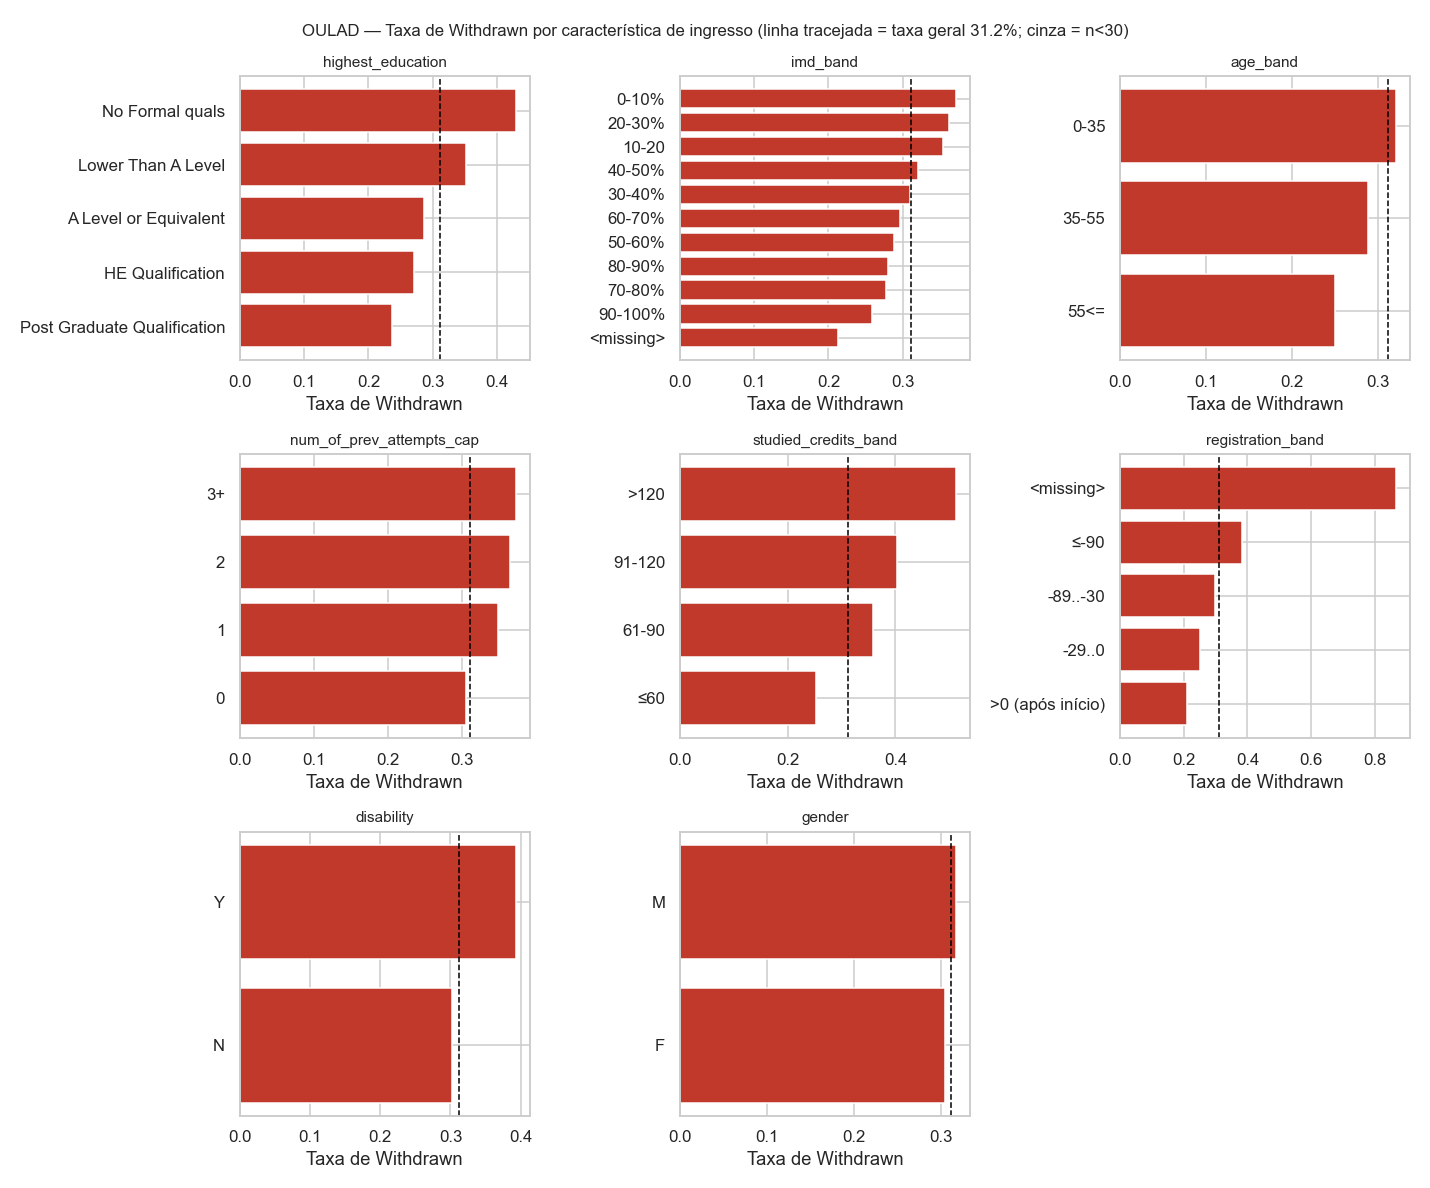

In [8]:
withdrawn = base['final_result'] == 'Withdrawn'
for col in ['highest_education', 'imd_band', 'age_band', 'disability']:
    display(eda.rate_by_category(base, col, withdrawn))
display(Image(FIG / 'oulad_withdrawal_rate_by_attribute.png'))

### Desempenho: 1ª avaliação não-final

Só estudantes ainda matriculados no prazo da avaliação.

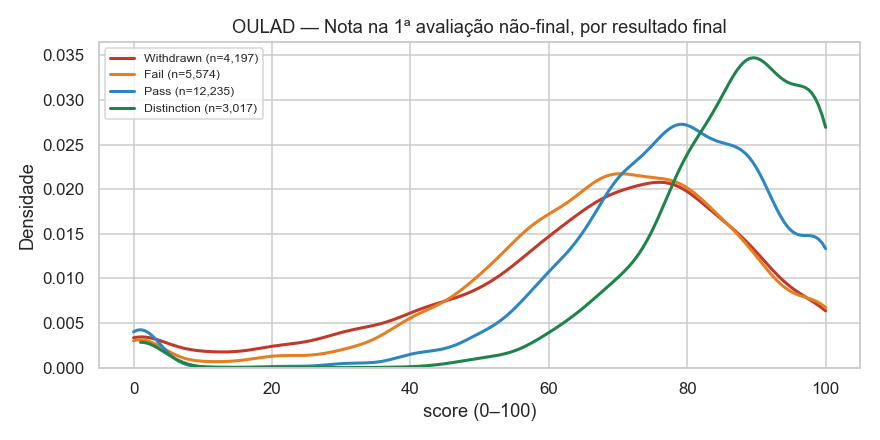

In [9]:
display(Image(FIG / 'oulad_first_assessment_score.png'))

### Qualidade do rótulo: `Fail` silencioso

Diagnóstico do **rótulo** usando o período inteiro (nunca usado como feature).

In [10]:
last = eda.last_activity_profile(sv, base)
last.assign(before_half=last['last_day_ratio'] < 0.5).groupby('final_result')['before_half'].mean().round(3)

final_result
Distinction    0.000
Fail           0.417
Pass           0.000
Withdrawn      0.561
Name: before_half, dtype: float64

## 3. Engajamento digital

In [11]:
weekly = temporal.weekly_clicks(sv)
wbo = eda.mean_weekly_clicks_by_outcome(weekly, base, range(-3, 40))
wbo[wbo['week'].between(1, 6)].pivot(index='week', columns='final_result', values='mean').round(1)

final_result,Distinction,Fail,Pass,Withdrawn
week,,,,
1,113.6,44.7,81.1,46.6
2,101.5,38.7,73.9,44.1
3,117.9,55.8,92.4,67.5
4,94.3,37.4,69.7,43.6
5,87.4,32.1,65.0,39.5
6,73.7,24.8,55.0,30.1


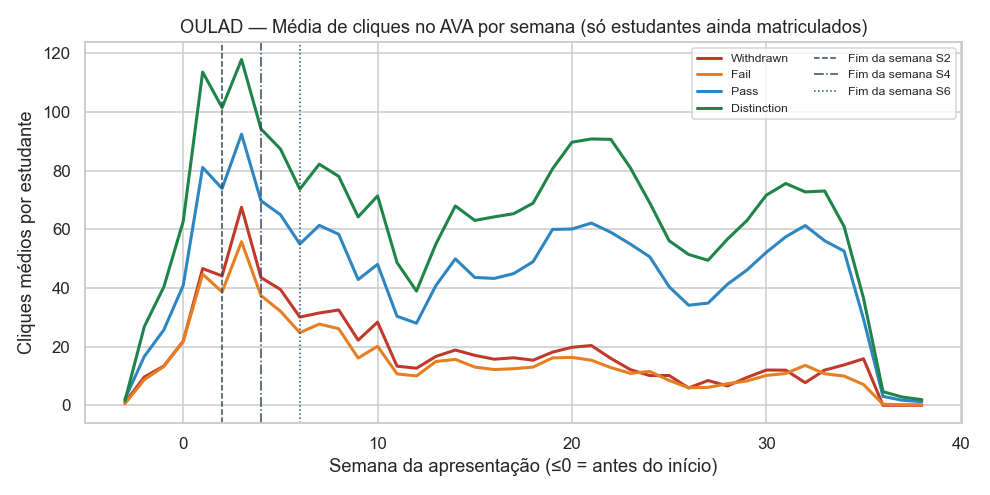

In [12]:
display(Image(FIG / 'oulad_weekly_clicks_by_outcome.png'))

,rel_week,mean,median,size,share_inactive
0,-8,31.173,4.0,4010,0.412
1,-7,29.253,3.0,4010,0.437
2,-6,26.835,2.0,4010,0.448
3,-5,22.094,1.0,4010,0.489
4,-4,19.397,0.0,4010,0.541
5,-3,14.543,0.0,4010,0.584
6,-2,12.227,0.0,4010,0.611
7,-1,11.762,0.0,4010,0.642
8,0,8.018,0.0,4010,0.646


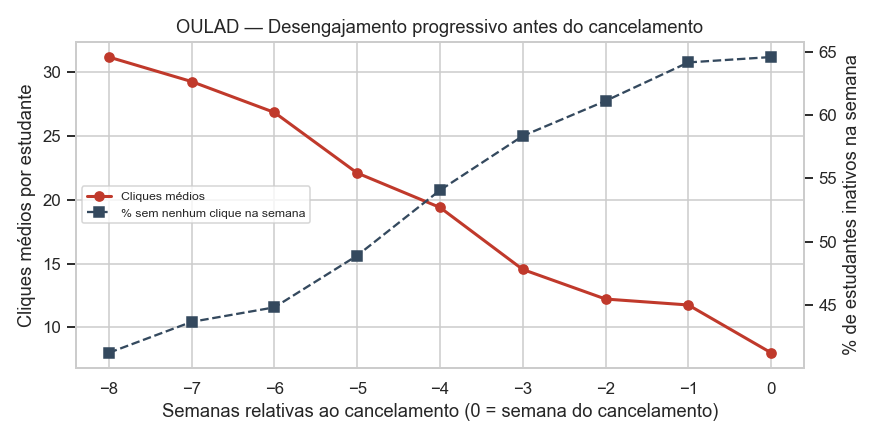

In [13]:
rel = eda.clicks_relative_to_withdrawal(weekly, base, weeks_before=8)
display(rel.round(3)); display(Image(FIG / 'oulad_disengagement_before_withdrawal.png'))

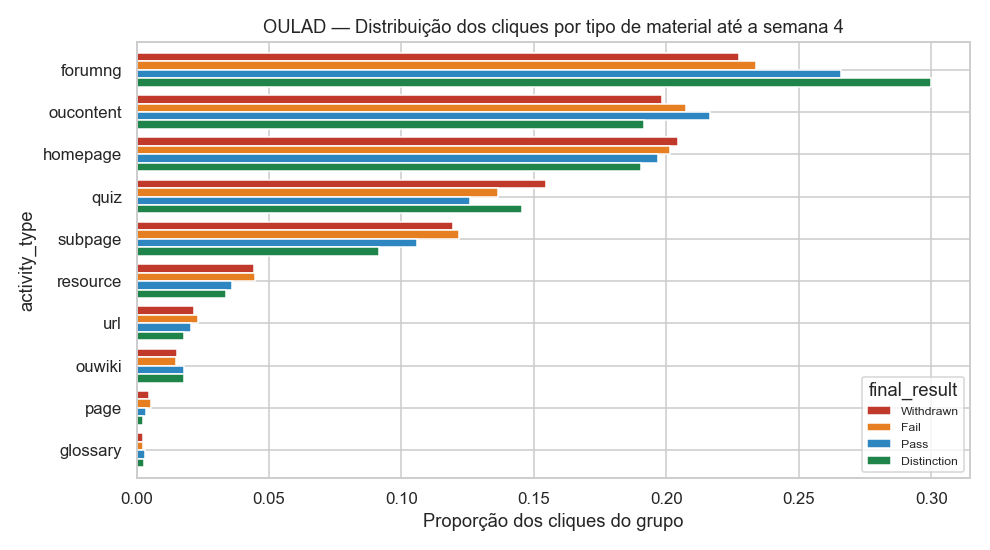

In [14]:
display(Image(FIG / 'oulad_activity_type_until_week4.png'))

**Leitura:** Withdrawn e Fail já clicam ~40–45% menos que Pass na semana 1; o desengajamento antes do cancelamento é progressivo (inatividade semanal 41% → 65% nas 8 semanas anteriores).